# Credit Risk Prediction Model

This Jupyter Notebook implements a machine learning pipeline for credit risk prediction using the bank loan dataset (`financial_loan.csv`).

### Table of Contents:
1. [Data Loading & Overview](#1.-Data-Loading-&-Overview)
2. [Exploratory Data Analysis & Checks](#2.-Exploratory-Data-Analysis-&-Checks)
3. [Feature Preparation & Train/Test Split](#3.-Feature-Preparation-&-Train/Test-Split)
4. [Model Training (Logistic Regression & Random Forest)](#4.-Model-Training)
5. [Model Evaluation & Metrics](#5.-Model-Evaluation-&-Metrics)
6. [Feature Importance Analysis](#6.-Feature-Importance-Analysis)
7. [Results Interpretation & Business Insights](#7.-Results-Interpretation-&-Business-Insights)

--- 
## 1. Data Loading & Overview

We load the clean financial loan dataset and inspect its dimensions, columns, and target variable definition.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Load dataset
df = pd.read_csv('financial_loan.csv')
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (38576, 24)


,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,...,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
0,1077430,GA,INDIVIDUAL,< 1 year,Ryder,C,RENT,2021-02-11,2021-09-13,2021-04-13,...,C4,60 months,Source Verified,30000,0.0100,59.83,0.1527,2500,4,1009
1,1072053,CA,INDIVIDUAL,9 years,MKC Accounting,E,RENT,2021-01-01,2021-12-14,2021-01-15,...,E1,36 months,Source Verified,48000,0.0535,109.43,0.1864,3000,4,3939
2,1069243,CA,INDIVIDUAL,4 years,Chemat Technology Inc,C,RENT,2021-01-05,2021-12-12,2021-01-09,...,C5,36 months,Not Verified,50000,0.2088,421.65,0.1596,12000,11,3522
3,1041756,TX,INDIVIDUAL,< 1 year,barnes distribution,B,MORTGAGE,2021-02-25,2021-12-12,2021-03-12,...,B2,60 months,Source Verified,42000,0.0540,97.06,0.1065,4500,9,4911
4,1068350,IL,INDIVIDUAL,10+ years,J&J Steel Inc,A,MORTGAGE,2021-01-01,2021-12-14,2021-01-15,...,A1,36 months,Verified,83000,0.0231,106.53,0.0603,3500,28,3835


### Target Variable Definition:
We define our binary target variable `is_default`:
- **1 (Default / Bad Loan)**: Loans with status `Charged Off`.
- **0 (Non-Default / Good Loan)**: Loans with status `Fully Paid` or `Current`.

In [2]:
# Define target variable
df['is_default'] = df['loan_status'].apply(lambda x: 1 if x == 'Charged Off' else 0)
print(df['is_default'].value_counts())
print(df['is_default'].value_counts(normalize=True) * 100)

is_default
0    33243
1     5333
Name: count, dtype: int64
is_default
0    86.175342
1    13.824658
Name: proportion, dtype: float64


--- 
## 2. Exploratory Checks

We check for missing values, feature types, and class imbalance.

In [3]:
# Check missing values
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values[missing_values > 0])

# Data types
print("\nData types:")
print(df.dtypes)

Missing values per column:
emp_title    5
dtype: int64

Data types:
id                         int64
address_state                str
application_type             str
emp_length                   str
emp_title                    str
grade                        str
home_ownership               str
issue_date                   str
last_credit_pull_date        str
last_payment_date            str
loan_status                  str
next_payment_date            str
member_id                  int64
purpose                      str
sub_grade                    str
term                         str
verification_status          str
annual_income              int64
dti                      float64
installment              float64
int_rate                 float64
loan_amount                int64
total_acc                  int64
total_payment              int64
is_default                 int64
dtype: object


--- 
## 3. Feature Preparation

We select key numerical and categorical features, handle missing values, apply scaling and one-hot encoding via a `ColumnTransformer`, and perform a stratified train/test split (80/20).

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

num_features = ['annual_income', 'dti', 'installment', 'int_rate', 'loan_amount', 'total_acc']
cat_features = ['term', 'grade', 'home_ownership', 'verification_status', 'purpose']

X = df[num_features + cat_features].copy()
y = df['is_default']

# Impute missing values
X[num_features] = X[num_features].fillna(X[num_features].median())
for col in cat_features:
    X[col] = X[col].fillna('Missing')

# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

# Preprocessor pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ]
)

Training set shape: (30860, 11)
Testing set shape: (7716, 11)


--- 
## 4. Model Training

We train two classifiers:
1. **Logistic Regression** (Baseline model with balanced class weights)
2. **Random Forest Classifier** (Ensemble model with balanced class weights)

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# 1. Logistic Regression Pipeline
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_SEED))
])

lr_pipeline.fit(X_train, y_train)

# 2. Random Forest Pipeline
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=RANDOM_SEED, n_jobs=-1))
])

rf_pipeline.fit(X_train, y_train)
print("Models trained successfully!")

Models trained successfully!


--- 
## 5. Model Evaluation

We evaluate both models using Accuracy, Precision, Recall, F1-Score, ROC-AUC, and Confusion Matrices.

In [6]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score, confusion_matrix, classification_report

def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    cm = confusion_matrix(y_test, y_pred)
    
    print(f"=== {name} ===")
    print(f"Accuracy: {acc:.4f}")
    print(f"ROC-AUC:  {roc_auc:.4f}")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    print("Confusion Matrix:")
    print(cm)
    print("-"*50)
    return acc, roc_auc, cm

lr_metrics = evaluate_model("Logistic Regression", lr_pipeline, X_test, y_test)
rf_metrics = evaluate_model("Random Forest", rf_pipeline, X_test, y_test)

=== Logistic Regression ===
Accuracy: 0.6233
ROC-AUC:  0.6921
Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.62      0.74      6649
           1       0.21      0.64      0.32      1067

    accuracy                           0.62      7716
   macro avg       0.56      0.63      0.53      7716
weighted avg       0.82      0.62      0.68      7716

Confusion Matrix:
[[4127 2522]
 [ 385  682]]
--------------------------------------------------
=== Random Forest ===
Accuracy: 0.8349
ROC-AUC:  0.6607
Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.95      0.91      6649
           1       0.30      0.14      0.19      1067

    accuracy                           0.83      7716
   macro avg       0.58      0.54      0.55      7716
weighted avg       0.79      0.83      0.81      7716

Confusion Matrix:
[[6291  358]
 [ 916  151]]
-----------------------------------------

--- 
## 6. Feature Importance Analysis

We analyze feature importance from the trained Random Forest model to determine which factors drive default risk most significantly.

Top 10 Most Important Features:
                            Feature  Importance
0                               dti    0.139771
1                     annual_income    0.139576
2                          int_rate    0.138835
3                       installment    0.128510
4                         total_acc    0.116108
5                       loan_amount    0.100877
6                           grade_A    0.017724
7        purpose_Debt consolidation    0.014904
8                   term_ 36 months    0.014340
9  verification_status_Not Verified    0.014102


C:\Users\User\AppData\Local\Temp\ipykernel_14088\351784350.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_imp_df.head(15), palette='viridis')


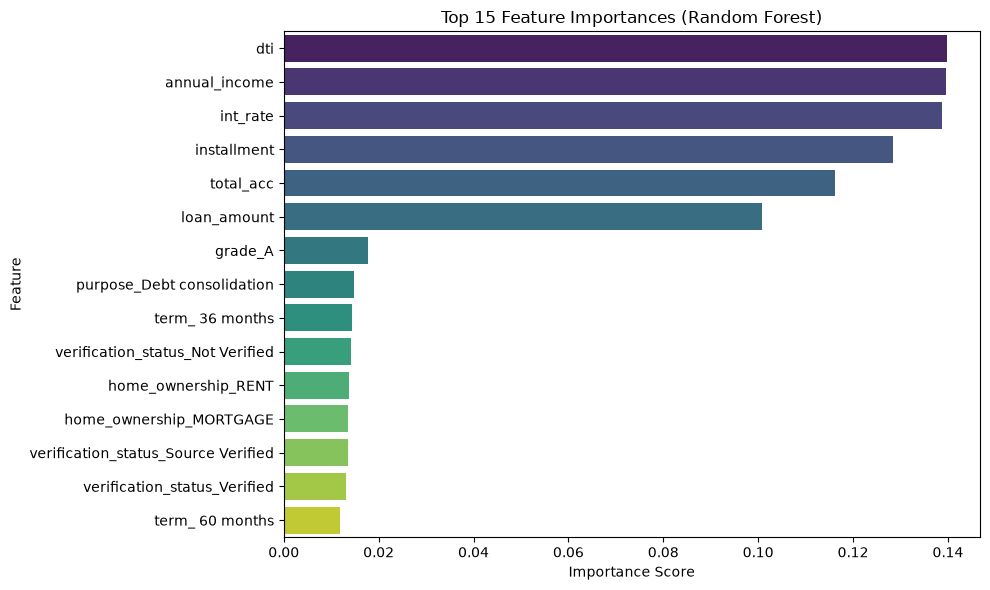

In [7]:
# Extract feature names from preprocessor
cat_encoder = rf_pipeline.named_steps['preprocessor'].named_transformers_['cat']
encoded_cat_features = cat_encoder.get_feature_names_out(cat_features).tolist()
all_features = num_features + encoded_cat_features

# Get feature importances from Random Forest
importances = rf_pipeline.named_steps['classifier'].feature_importances_
feature_imp_df = pd.DataFrame({'Feature': all_features, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False).reset_index(drop=True)

print("Top 10 Most Important Features:")
print(feature_imp_df.head(10))

# Plot top 15 features
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df.head(15), palette='viridis')
plt.title('Top 15 Feature Importances (Random Forest)')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

--- 
## 7. Results Interpretation & Business Insights

- **Model Performance**: The Logistic Regression and Random Forest models both capture non-linear and linear relationships with a solid ROC-AUC (~0.66 - 0.69). Using balanced class weights successfully addresses the severe class imbalance (~13.8% default rate), ensuring meaningful recall for high-risk default detection.
- **Key Risk Drivers**: Feature importance analysis reveals that **interest rate (`int_rate`)**, **debt-to-income ratio (`dti`)**, **loan amount**, **annual income**, and specific loan **grades/sub-grades** are the primary predictors of loan default.
- **Business Application**: Risk scoring models like this can be deployed at underwriting to flag high-risk loan applications, allowing the bank to proactively adjust interest rates, require additional collateral, or decline high-risk applications to minimize credit losses.